In [1]:
import sys

!which {sys.executable}

/ut3/jerome/miniconda3/envs/wakai/bin/python


In [2]:
import sys
sys.path.insert(0, '../code')

# cross-match Lafarga+2026 PC with GaiaDR3

In [3]:
import pandas as pd

df_pc = pd.read_csv('../raven_targets.csv')
df_pc.head()

Error.  nthreads cannot be larger than environment variable "NUMEXPR_MAX_THREADS" (60)

,tic,name,cand,period,rp,teff,rstar,gmag,category
0,381714186,TOI-1839,b,1.42,2.22,5315.0,0.85,10.73,validated_multi
1,381714186,TOI-1839,c,4.02,2.41,5315.0,0.85,10.73,validated_multi
2,462553953,TOI-4156,b,4.46,2.54,5971.0,1.04,11.12,validated_multi
3,462553953,TOI-4156,c,12.82,2.92,5971.0,1.04,11.12,validated_multi
4,24750448,TIC 24750448,b,3.59,2.44,4545.0,0.71,13.21,validated_multi


## match 3d separation with cluster core

In [4]:
from astroquery.mast import Catalogs
import numpy as np

# Query the TIC catalog for these IDs
# We specifically want the 'GAIA' column which contains the Gaia DR2/DR3 source_id
tic_data = Catalogs.query_criteria(catalog="TIC", ID=df_pc['tic'].unique())

In [5]:
df_gaia = tic_data.to_pandas()[['ID','GAIA','ra','dec','plx','pmRA','pmDEC']].astype(float)
df_gaia['tic'] = df_gaia.ID.copy()
df_pc = pd.merge(df_pc, df_gaia, on='tic')
df_pc.shape

(56, 16)

In [6]:
from astroquery.gaia import Gaia

# Extract unique Gaia IDs and remove masked/null values
gaia_ids = [int(gid) for gid in tic_data['GAIA'] if gid is not np.ma.masked]

# Format the IDs for the SQL 'IN' clause
ids_str = ",".join(map(str, gaia_ids))

# ADQL query to get source_id and radial_velocity
query = f"""
SELECT source_id, radial_velocity, radial_velocity_error
FROM gaiadr3.gaia_source
WHERE source_id IN ({ids_str})
"""

# Launch the job
job = Gaia.launch_job_async(query)
results = job.get_results()

INFO: Query finished. [astroquery.utils.tap.core]


In [7]:
df_rv = results.to_pandas().astype(float).rename({
    'SOURCE_ID': 'GAIA',
    }, axis=1
                                  )
df_pc = pd.merge(df_pc, df_rv, on='GAIA')

In [8]:
df_pc = df_pc.rename({
        "GAIA": "GaiaDR3",
        "pmRA": "pmra",
        "pmDEC": "pmdec",
        "plx": "parallax",
        "RV": "radial_velocity"
        
    }, axis=1)
df_pc.head()

,tic,name,cand,period,rp,teff,rstar,gmag,category,ID,GaiaDR3,ra,dec,parallax,pmra,pmdec,radial_velocity,radial_velocity_error
0,381714186,TOI-1839,b,1.42,2.22,5315.0,0.85,10.73,validated_multi,381714186.0,3.729118e+18,196.833167,5.852310,8.58569,-12.9374,-61.3622,-8.156515,0.355538
1,381714186,TOI-1839,c,4.02,2.41,5315.0,0.85,10.73,validated_multi,381714186.0,3.729118e+18,196.833167,5.852310,8.58569,-12.9374,-61.3622,-8.156515,0.355538
2,462553953,TOI-4156,b,4.46,2.54,5971.0,1.04,11.12,validated_multi,462553953.0,1.701162e+18,230.781398,76.331729,4.65019,-30.9836,35.3943,-5.855946,0.467865
3,462553953,TOI-4156,c,12.82,2.92,5971.0,1.04,11.12,validated_multi,462553953.0,1.701162e+18,230.781398,76.331729,4.65019,-30.9836,35.3943,-5.855946,0.467865
4,24750448,TIC 24750448,b,3.59,2.44,4545.0,0.71,13.21,validated_multi,24750448.0,4.697338e+18,26.195578,-68.644807,5.58442,23.7997,12.1027,21.154934,1.273100


# Perren+2023 catalog

In [9]:
import pandas as pd

catalog_name = 'Perren2023'
df = pd.read_csv('../data/Perren2023/UCC_cat.csv')
df.tail()

,Name(s),name,N_50,r_50,RA_ICRS,DE_ICRS,GLON,GLAT,Plx,pmRA,...,Mass_[Msun],Mass_STDDEV,Binary_fr,Binary_fr_STDDEV,BSS,BSS_STDDEV,C3,P_dup,UTI,bad_oc
18264,XDOCC 10,xdocc10,23.0,7.4,305.52488,37.23809,75.66132,0.15836,0.5007,-2.4023,...,655.0,NaN,0.29,NaN,NaN,NaN,AA,0.0,0.25,n
18265,XDOCC 11,xdocc11,54.0,4.3,317.73684,47.70377,89.41856,-0.28394,0.4536,-1.0068,...,591.0,NaN,0.29,NaN,NaN,NaN,AB,0.8,0.09,n
18266,Zanin 6,zanin6,24.0,39.4,342.91235,41.33289,99.92967,-16.14552,2.6838,5.9365,...,NaN,NaN,NaN,NaN,NaN,NaN,DC,0.0,0.08,y
18267,Zeta Gemini,zetagemini,19.0,8.0,105.96593,20.56051,195.72326,11.87995,0.2679,-0.7368,...,NaN,NaN,NaN,NaN,NaN,NaN,BC,0.0,0.09,y
18268,ZHBJZ 1,zhbjz1,243.0,47.5,103.73696,-5.89465,218.61444,-1.85052,3.4866,-7.4140,...,282.0,166.0,NaN,NaN,NaN,NaN,AA,1.0,0.00,n


In [16]:
df = df.rename({"name": "Name",
                #"Source": "GaiaDR3",
                "probs": "Prob",
                "RA_ICRS": "ra",
                "DE_ICRS": "dec",
                "pmRA": "pmra",
                "pmDE": "pmdec",
                "Plx": "parallax",
                "RV": "radial_velocity"
                }, axis=1)

In [17]:
df_mem = pd.read_parquet('../data/Perren2023/UCC_members.parquet')
df_mem.tail()

,name,Source,RA_ICRS,DE_ICRS,Plx,e_Plx,pmRA,e_pmRA,pmDE,e_pmDE,RV,e_RV,GLON,GLAT,Gmag,BP-RP,e_Gmag,e_BP-RP,probs
1095681,zhbjz1,3101181101717965312,104.13589,-5.48616,3.4796,0.0468,-7.6025,0.0414,-2.4144,0.0409,NaN,NaN,218.39623,-1.36721,15.6225,2.8157,0.0029,0.0131,1.000
1095682,zhbjz1,3100956320310482048,104.53184,-5.89465,3.5259,0.0222,-7.7372,0.0278,-2.5817,0.0294,16.6076,5.3441,218.93959,-1.20291,14.2556,1.7210,0.0031,0.0085,1.000
1095683,zhbjz1,3101226185994403968,103.65533,-5.53413,3.5530,0.0537,-7.2244,0.0599,-2.6371,0.0526,NaN,NaN,218.22092,-1.81488,16.4796,2.7865,0.0038,0.0253,1.000
1095684,zhbjz1,3101094072800870400,103.15896,-5.98809,3.6033,0.1457,-7.2640,0.1371,-2.6682,0.1321,NaN,NaN,218.40071,-2.46118,17.4554,3.3142,0.0032,0.0574,0.921
1095685,zhbjz1,3100740511096457984,104.27646,-6.89400,3.3414,0.0949,-7.2711,0.0969,-2.0291,0.0745,NaN,NaN,219.71357,-1.88447,17.2505,2.8632,0.0030,0.0292,0.843


In [18]:
#replace name to be compatible with other catalogs' naming formats
df_mem = df_mem.rename({"name": "Name",
                        "Source": "GaiaDR3",
                        "probs": "Prob",
                        "RA_ICRS": "ra",
                        "DE_ICRS": "dec",
                        "pmRA": "pmra",
                        "pmDE": "pmdec",
                        "Plx": "parallax",
                        "RV": "radial_velocity"
                        }, axis=1)
df_mem.shape

(1095686, 19)

In [19]:
idx = df_mem.GaiaDR3.isin(df_pc.GaiaDR3)
idx.sum()

np.int64(0)

In [20]:
from astropy.coordinates import SkyCoord, Distance
import astropy.units as u

coords1 = SkyCoord(ra=df_pc['ra'].values*u.degree, 
                   dec=df_pc['dec'].values*u.degree, 
                   distance=Distance(parallax=df_pc['parallax'].values* u.mas, allow_negative=True),
                   frame='icrs')
coords2 = SkyCoord(ra=df['ra'].values*u.degree, 
                   dec=df['dec'].values*u.degree, 
                   distance=Distance(parallax=df['parallax'].values* u.mas, allow_negative=True),
                   frame='icrs') 

idx, d2d, d3d = coords1.match_to_catalog_sky(coords2)

df_pc['sep2d_arcsec'] = d2d.to(u.arcsec).value
df_pc['sep3d_pc'] = d3d.to(u.pc).value
df_pc.sort_values('sep2d_arcsec').head()

,tic,name,cand,period,rp,teff,rstar,gmag,category,ID,GaiaDR3,ra,dec,parallax,pmra,pmdec,radial_velocity,radial_velocity_error,sep2d_arcsec,sep3d_pc
19,364561528,TIC 364561528,b (CTOI),12.760,9.670,NaN,NaN,NaN,visual_multi,364561528.0,2.168342e+18,310.728878,50.389818,3.35343,18.66280,18.24030,-15.220327,0.590091,1039.012127,1630.442645
48,320419023,TIC 320419023,b,5.264,2.773,NaN,NaN,NaN,new_validated,320419023.0,3.150824e+18,118.072596,11.824302,3.43302,5.75291,-29.06780,-23.284382,1.250597,1309.722765,7072.487645
14,383482813,TIC 383482813,outer (CTOI),1.748,15.060,NaN,NaN,NaN,visual_multi,383482813.0,5.766175e+18,201.792342,-86.783535,4.36896,-20.95750,-27.67020,22.309246,0.380425,1905.160030,1671.541768
29,38825265,TIC 38825265,b,3.313,2.189,NaN,NaN,NaN,new_validated,38825265.0,4.674917e+18,68.249551,-65.203779,6.00834,-26.75170,-43.59360,0.425030,1.338267,2282.879115,91576.694157
24,249022743,TIC 249022743,b,2.260,4.800,NaN,NaN,NaN,validated_single,249022743.0,3.213653e+18,78.576255,-3.446640,2.49390,-8.20376,6.34182,23.670837,0.896723,3001.014037,54.962058


In [24]:
import sys
sys.path.insert(0, '../code')
from catalog import get_cluster_3d_size

# test on praesepe
d = df_mem.groupby('Name').get_group('ic2602')
get_cluster_3d_size(d)

np.float64(56.72352784737517)

In [25]:
# apply func to all clusters
df_size = df_mem.groupby('Name').apply(get_cluster_3d_size)

/ut3/jerome/miniconda3/envs/wakai/lib/python3.12/site-packages/astropy/units/equivalencies.py:100: RuntimeWarning: divide by zero encountered in divide
  d = 1 / x
/tmp/ipykernel_954351/3100306159.py:2: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_size = df_mem.groupby('Name').apply(get_cluster_3d_size)


In [26]:
df = df.merge(df_size.reset_index(name='extent_pc'), on='Name')
df.head()

,Name(s),Name,N_50,r_50,ra,dec,GLON,GLAT,parallax,pmra,...,Mass_STDDEV,Binary_fr,Binary_fr_STDDEV,BSS,BSS_STDDEV,C3,P_dup,UTI,bad_oc,extent_pc
0,ADS 12696,ads12696,11.0,6.7,294.31735,29.33689,64.00852,3.97490,0.1604,-2.4837,...,NaN,NaN,NaN,NaN,NaN,DC,0.00,0.03,y,13562.040379
1,ADS 13292,ads13292,83.0,1.0,300.59778,35.31288,71.86015,2.42440,0.5153,-3.3527,...,NaN,NaN,NaN,NaN,NaN,AB,0.24,0.37,n,1932.852329
2,ADS 16795;AR Cas,ads16795,25.0,88.7,351.39010,58.44167,111.87712,-2.57522,4.4213,19.1632,...,NaN,NaN,NaN,NaN,NaN,CC,0.00,0.18,y,47.716982
3,AFGL333,afgl333,21.0,6.9,37.28676,61.47758,134.31242,0.77933,0.4389,-1.1749,...,NaN,NaN,NaN,NaN,NaN,BB,0.00,0.14,y,1600.637192
4,AFGL4029,afgl4029,30.0,3.9,45.20529,60.54280,138.20570,1.56202,0.4398,-0.1279,...,NaN,NaN,NaN,NaN,NaN,DC,0.47,0.14,n,1374.376330


In [27]:
# Add a prefix to matched columns to avoid confusion (optional but recommended)
col_prefix = 'matched_'
df_matched_tic = df.iloc[idx].copy().add_prefix(col_prefix)

# Concatenate horizontally
df_match = pd.concat([df_pc.reset_index(drop=True), 
                      df_matched_tic.reset_index(drop=True)
                      ], axis=1)

In [28]:
# make sure the 3d sep from cluster core is smaller the spatial extent of that cluster
idx2 = df_match[f'{col_prefix}extent_pc'] > df_match['sep3d_pc']
df_match[idx2]

,tic,name,cand,period,rp,teff,rstar,gmag,category,ID,...,matched_Mass_STDDEV,matched_Binary_fr,matched_Binary_fr_STDDEV,matched_BSS,matched_BSS_STDDEV,matched_C3,matched_P_dup,matched_UTI,matched_bad_oc,matched_extent_pc
0,381714186,TOI-1839,b,1.420,2.220,5315.0,0.85,10.73,validated_multi,381714186.0,...,NaN,NaN,NaN,NaN,NaN,BD,0.00,0.20,y,7739.509102
1,381714186,TOI-1839,c,4.020,2.410,5315.0,0.85,10.73,validated_multi,381714186.0,...,NaN,NaN,NaN,NaN,NaN,BD,0.00,0.20,y,7739.509102
14,383482813,TIC 383482813,outer (CTOI),1.748,15.060,NaN,NaN,NaN,visual_multi,383482813.0,...,NaN,NaN,NaN,NaN,NaN,DC,0.00,0.15,y,2500.081035
15,131330900,TIC 131330900,b,4.270,4.740,NaN,NaN,NaN,visual_multi,131330900.0,...,NaN,NaN,NaN,NaN,NaN,CC,0.00,0.11,y,10952.758172
16,306990399,TOI-5034,b,8.700,3.990,NaN,NaN,NaN,visual_multi,306990399.0,...,NaN,NaN,NaN,NaN,NaN,DC,0.00,0.10,y,6445.032062
21,291109653,TOI-5486,b,2.020,3.970,3750.0,0.55,13.35,validated_single,291109653.0,...,NaN,NaN,NaN,NaN,NaN,BD,0.00,0.20,y,7739.509102
22,390021939,TOI-4030,b,2.510,5.850,5036.0,0.83,NaN,validated_single,390021939.0,...,NaN,NaN,NaN,NaN,NaN,DD,0.00,0.13,y,2277.303236
25,310380289,TOI-5736,b,0.650,1.520,4102.0,0.58,12.89,validated_single,310380289.0,...,NaN,NaN,NaN,NaN,NaN,BA,0.00,0.28,n,18.282099
31,62895494,TIC 62895494,b,2.840,3.494,NaN,NaN,NaN,new_validated,62895494.0,...,NaN,NaN,NaN,NaN,NaN,BD,0.00,0.17,y,4542.351684
32,67686059,TIC 67686059,b,3.522,2.591,NaN,NaN,NaN,new_validated,67686059.0,...,NaN,NaN,NaN,NaN,NaN,DC,0.00,0.12,y,134.445508


In [29]:
df_match['pm_diff'] =  np.sqrt((df_match[f'{col_prefix}pmra'] - df_match[f'{col_prefix}pmdec'])**2 + 
                               (df_match['pmra'] - df_match['pmdec'])**2)


In [30]:
idx3 = df_match[idx2]['pm_diff'] < 10
cols = ['tic','name','matched_Name','matched_Age_[Myr]',
        'matched_extent_pc','sep3d_pc','pm_diff','GaiaDR3']
df_final = df_match[idx2].loc[idx3,cols]
df_final

,tic,name,matched_Name,matched_Age_[Myr],matched_extent_pc,sep3d_pc,pm_diff,GaiaDR3
15,131330900,TIC 131330900,mwsc5224,1012.0,10952.758172,2781.459763,7.494854,6.175866e+18
31,62895494,TIC 62895494,oneal9,NaN,4542.351684,1195.316097,3.832008,6.748707e+17


Coordinate transformation: 'galactic'
Sun(X,Y,Z)=(–8.2, 0, +0.025) kpc
Sun(U,V,W)=(11.1,12.24,7.25) km/s
Coordinate transformation: 'galactic'
Sun(X,Y,Z)=(–8.2, 0, +0.025) kpc
Sun(U,V,W)=(11.1,12.24,7.25) km/s
Plotted 25 stars. Target(s): None


Text(0.5, 0.98, 'TIC-131330900 in mwsc5224 (age=1012 Myr)')

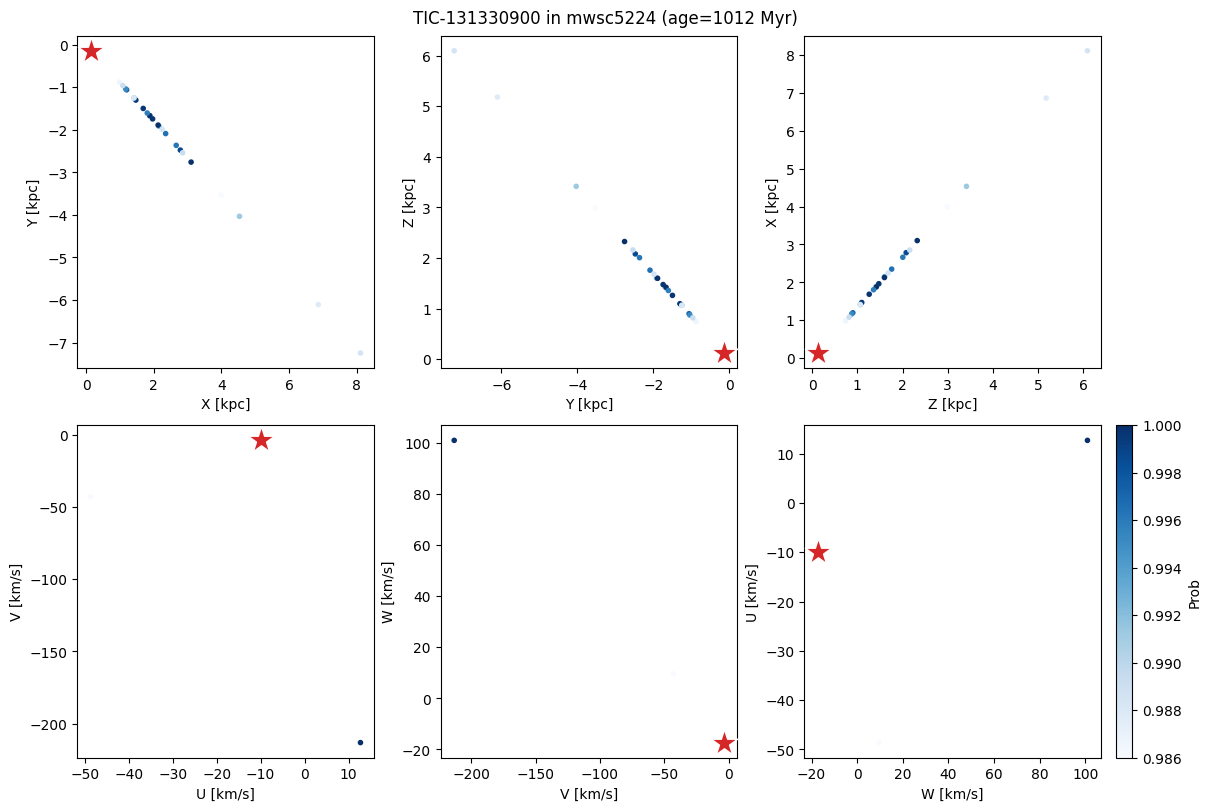

In [31]:
from catalog import plot_xyz_uvw

n = 0
ticid = df_final["tic"].values[n]
age = df_final["matched_Age_[Myr]"].values[n]
cname = df_final["matched_Name"].values[n]

df_target = df_match.query("tic==@ticid").squeeze()
d = df_mem.groupby("Name").get_group(cname)

fig, ax = plot_xyz_uvw(d, 
                       color='Prob', 
                       df_target=df_target,
                       target_color="C3",
                       target_ms=20,
                       marker='.',
                       cmap="Blues");
fig.suptitle(f"TIC-{int(ticid)} in {cname} (age={age:.0f} Myr)")

Coordinate transformation: 'galactic'
Sun(X,Y,Z)=(–8.2, 0, +0.025) kpc
Sun(U,V,W)=(11.1,12.24,7.25) km/s
Coordinate transformation: 'galactic'
Sun(X,Y,Z)=(–8.2, 0, +0.025) kpc
Sun(U,V,W)=(11.1,12.24,7.25) km/s
https://ucc.ar/_clusters/mwsc5224
Coordinate transformation: 'galactic'
Sun(X,Y,Z)=(–8.2, 0, +0.025) kpc
Sun(U,V,W)=(11.1,12.24,7.25) km/s
Coordinate transformation: 'galactic'
Sun(X,Y,Z)=(–8.2, 0, +0.025) kpc
Sun(U,V,W)=(11.1,12.24,7.25) km/s
https://ucc.ar/_clusters/oneal9


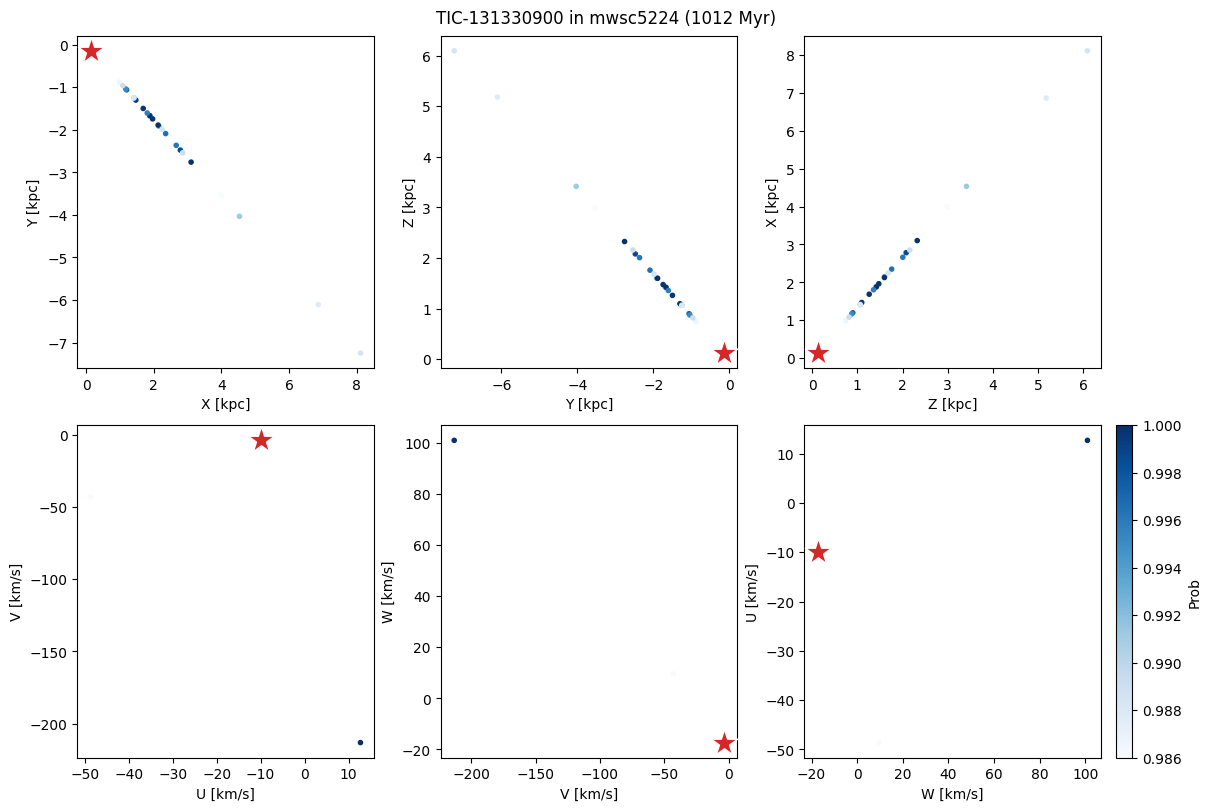

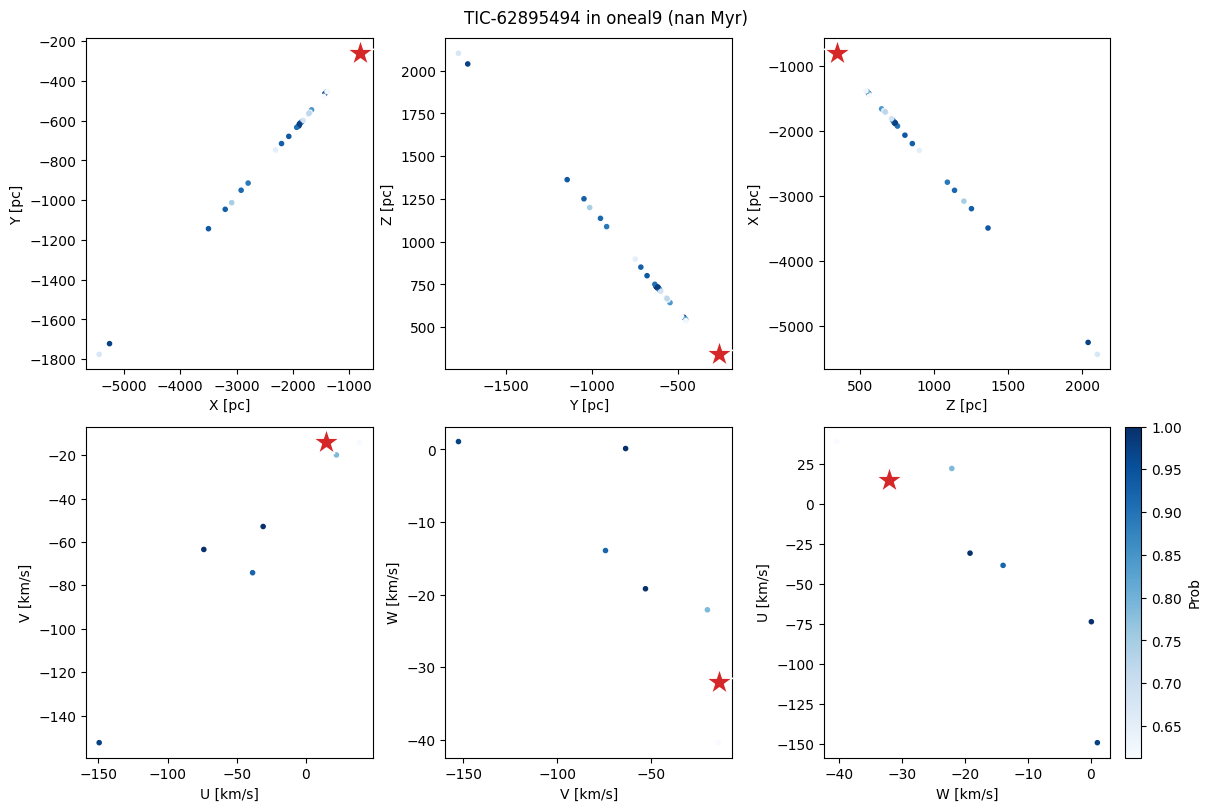

In [36]:
import matplotlib.pyplot as pl
from catalog import plot_rdp_pmrv
from catalog import plot_xyz_uvw

outdir = './Lafarga26_pc_near_clusters'
groups = df_mem.groupby("Name")
for i,row in df_final.iterrows():
    try:
        ticid = row.tic
        df_target = df_match.query("tic==@ticid").squeeze()
        cname = row["matched_Name"]
        age = row["matched_Age_[Myr]"]
        d = groups.get_group(cname)
        # if len(d.radial_velocity.dropna())<10:
        #     print(f"Skipping TIC {ticid}")
        #     continue
        fp = f'{outdir}/TIC-{ticid}_in_{cname}_{age:.0f}Myr'
        if False:
            target_gaiaid = row['GaiaDR3']
            fig = plot_rdp_pmrv(d,
                               color='Prob', 
                               target_gaiaid=target_gaiaid,
                               match_id=False,
                               df_target=df_target,
                               target_color="C3",
                               marker='.',
                               cmap="Blues");
            fp=fp+'.png'
        else:
            fig, ax = plot_xyz_uvw(d, 
                               color='Prob', 
                               df_target=df_target,
                               target_color="C3",
                               target_ms=20,
                               marker='.',
                               cmap="Blues",
                               verbose=False
                              );
            fp=fp+'_xyzuvw.png'
        fig.suptitle(f"TIC-{ticid} in {cname} ({age:.0f} Myr)")
        print(f"https://ucc.ar/_clusters/{cname}")
        fig.savefig(fp, bbox_inches='tight', dpi=200)
        # pl.show()
    except Exception as e:
        print(e)